### Top Rows

In [348]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display, HTML

def display_scroll(df, height="400px"):
    display(HTML(f"""
    <div style="max-height:{height}; overflow:auto; border:1px solid #ccc; padding:5px;">
        {df.to_html()}
    </div>
    """))
file_path = "results-filtered.xlsx"
df = pd.read_excel(file_path, sheet_name="kPEX")
# df = pd.read_excel(file_path, sheet_name="UMKP+AltRB")
# versions="v0 v1 v2 v3 v4".split()
versions="v0 v1 v2 v3".split()
branchings="S R P".split()

for v in versions: 
    df[f"{v}-prep"] = (df[f"{v}-S-bnb"] == "prep")
    cols = [f"{v}-{b}-ctcp" for b in branchings]
    df[f"{v}-ctcp"] = (
        df[cols]
        .apply(pd.to_numeric, errors="coerce")  # non-numeric → NaN
        .mean(axis=1)                           # skips NaN automatically
    )
    cols = [f"{v}-{b}-heur" for b in branchings]
    df[f"{v}-heur"] = (
        df[cols]
        .apply(pd.to_numeric, errors="coerce")  # non-numeric → NaN
        .mean(axis=1)                           # skips NaN automatically
    )    

    
def clean_dataframe(df):
    df = df.dropna(axis=1, how="all")
    df = df.copy()

    def convert_col(col):
        # replace exact matches first
        col = col.replace({"x": 1800, "prep": 0})
        
        # try numeric conversion WITHOUT destroying original values
        numeric = pd.to_numeric(col, errors="coerce")
        
        # keep original where conversion failed
        return numeric.where(~numeric.isna(), col)

    return df.apply(convert_col)

df = clean_dataframe(df)

for v in versions: 
    df[f"{v}-init"] = df[f"{v}-heur"]+df[f"{v}-ctcp"]
    df[f"{v}-prep"] = df[f"{v}-prep"].replace(False, "")
    
df.head()
pd.set_option('display.float_format', '{:.1f}'.format)
pd.set_option('display.max_rows', 50)
pd.set_option('display.max_columns', None)

/var/folders/fg/pzhds6gn509_r3cmd5yf1hnm0000gq/T/ipykernel_38912/6664473.py:41: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  col = col.replace({"x": 1800, "prep": 0})
/var/folders/fg/pzhds6gn509_r3cmd5yf1hnm0000gq/T/ipykernel_38912/6664473.py:41: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  col = col.replace({"x": 1800, "prep": 0})
/var/folders/fg/pzhds6gn509_r3cmd5yf1hnm0000gq/T/ipykernel_38912/6664473.py:41: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the ol

In [349]:
# for v in versions: 
cols = [f"v0-{b}-mkp" for b in "S R P".split() ]
cols = [f"v{i}-{b}-mkp" for i in [0, 1] for b in "S R P".split() ]

mask = df[cols].apply(lambda row: row[row != 1800].nunique() > 1, axis=1)
display_scroll(df.loc[mask, cols+["dataset", "k", "v1-S-total"]])
filtered_df = df[mask]

filtered_df[["dataset", "k"]].to_excel("filtered_rows.xlsx", index=False)
mask.sum()

,v0-S-mkp,v0-R-mkp,v0-P-mkp,v1-S-mkp,v1-R-mkp,v1-P-mkp,dataset,k,v1-S-total


np.int64(0)

### Varying Ratio Threshold


=== Threshold 1.5 Analysis ===
v0-S-total wins: 379
v2-S-total wins: 501

--- Weaker side: v0-S-total ---


,dataset,k,v0-S-total,v2-S-total,speedup,v0-ctcp,v2-ctcp,v0-heur,v2-heur,v0-init,v2-init,v0-prep,v2-prep,v0-S-total,v2-S-total,v0-R-total,v2-R-total,v0-P-total,v2-P-total
314,bag-pubmed,4,1186.2,1800.0,1.52x,1069.7,NaN,113.8,NaN,1183.4,NaN,True,,1186.2,1800.0,1181.6,1800.0,1182.5,1800.0
2854,rec-epinions-user-ratings,20,1183.9,1800.0,1.52x,7.1,7.1,2.9,0.2,10.0,7.3,,,1183.9,1800.0,232.9,77.9,129.7,1800.0
1108,edit-plwiki,6,1146.7,1800.0,1.57x,2.7,2.6,7.3,0.2,10.0,2.8,,,1146.7,1800.0,612.9,1516.4,1518.6,1800.0
3843,Trec12,10,1139.8,1800.0,1.58x,0.1,NaN,0.5,NaN,0.6,NaN,,,1139.8,1800.0,1800.0,1800.0,1344.6,1800.0
3561,soc-sinaweibo,4,1102.2,1800.0,1.63x,85.9,79.9,32.8,6.3,118.6,86.3,,,1102.2,1800.0,1800.0,1800.0,358.9,607.4
3508,soc-orkut,10,1036.2,1800.0,1.74x,20.7,20.4,0.2,0.2,20.9,20.5,,,1036.2,1800.0,1800.0,1800.0,21.5,21.6
3487,soc-livejournal-user-grou...,10,1019.6,1800.0,1.77x,721.2,NaN,254.6,NaN,975.8,NaN,,,1019.6,1800.0,1020.4,1800.0,1019.7,1800.0
313,bag-pubmed,3,871.4,1612.4,1.85x,761.1,757.1,107.6,111.1,868.7,868.2,True,,871.4,1612.4,868.7,1614.7,866.1,1607.0
489,bibd_18_9,20,823.9,1800.0,2.18x,2.0,2.0,0.9,0.0,3.0,2.0,,,823.9,1800.0,8.6,63.4,5.9,8.4
3656,sx-stackoverflow,5,787.5,1562.8,1.98x,5.6,5.6,0.2,0.0,5.8,5.6,,,787.5,1562.8,1800.0,1800.0,6.7,6.5



--- Stronger side: v2-S-total ---


,dataset,k,v0-S-total,v2-S-total,speedup,v0-ctcp,v2-ctcp,v0-heur,v2-heur,v0-init,v2-init,v0-prep,v2-prep,v0-S-total,v2-S-total,v0-R-total,v2-R-total,v0-P-total,v2-P-total
4217,wikipedia-link-en13,4,606.5,309.5,1.96x,365.1,304.9,116.4,1.5,481.5,306.4,True,,606.5,309.5,427.7,300.3,410.3,309.7
1843,karted,4,374.6,226.5,1.65x,0.3,0.3,149.1,0.1,149.4,0.3,,,374.6,226.5,374.9,225.3,375.0,225.9
1844,karted,5,472.9,221.6,2.13x,0.2,0.2,247.9,0.1,248.1,0.3,,,472.9,221.6,473.5,222.7,474.6,221.8
885,degme,5,281.7,165.2,1.71x,0.1,0.1,115.4,0.1,115.6,0.2,,,281.7,165.2,281.9,165.1,280.9,164.8
2010,lp_osa_30,6,502.4,132.0,3.81x,0.0,0.0,366.4,0.0,366.5,0.0,,,502.4,132.0,498.1,131.1,493.0,131.3
3971,TSOPF_FS_b39_c30,6,208.8,110.5,1.89x,0.1,0.1,97.9,0.0,98.0,0.2,,,208.8,110.5,208.3,110.6,208.4,110.6
3970,TSOPF_FS_b39_c30,5,205.7,105.5,1.95x,0.1,0.1,100.4,0.1,100.5,0.2,,,205.7,105.5,205.6,105.5,206.9,105.4
3972,TSOPF_FS_b39_c30,7,201.2,105.4,1.91x,0.1,0.1,96.0,0.0,96.2,0.2,,,201.2,105.4,201.1,105.4,201.3,105.2
3968,TSOPF_FS_b39_c30,3,196.2,98.5,1.99x,0.1,0.2,103.7,0.1,103.9,0.2,,,196.2,98.5,194.4,91.7,195.1,91.4
3969,TSOPF_FS_b39_c30,4,198.9,97.2,2.05x,0.1,0.1,101.8,0.1,101.9,0.2,,,198.9,97.2,199.3,97.2,198.5,97.1


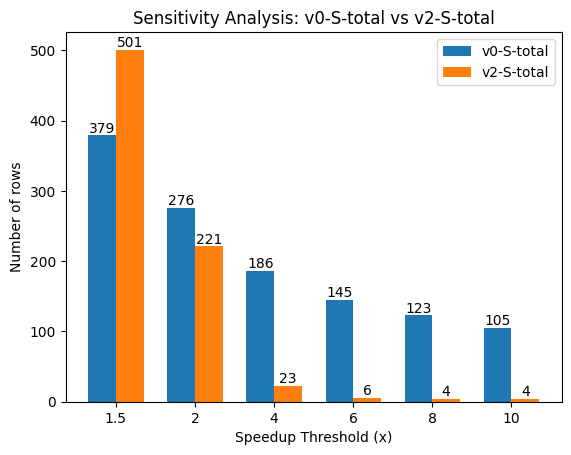

In [353]:
# =========================
# CONFIG
# =========================

col_a = "v0-S-total"
col_b = "v2-S-total"
va = col_a.split("-")[0]
vb = col_b.split("-")[0]
thresholds = [1.5, 2, 4, 6, 8, 10]
min_time_threshold = 1.0

# =========================
# Handle zeros
# =========================
df = df.replace(0, 0.01)

# =========================
# Filter
# =========================
df_filtered = df[
    (df[col_a] >= min_time_threshold) | (df[col_b] >= min_time_threshold)
].copy()

# =========================
# Compute speedups
# =========================
df_filtered["speedup_a"] = df_filtered[col_b] / df_filtered[col_a]
df_filtered["speedup_b"] = df_filtered[col_a] / df_filtered[col_b]

# =========================
# Threshold = 2 analysis
# =========================
threshold_check = thresholds[0]

a_wins = df_filtered[df_filtered["speedup_a"] >= threshold_check].copy()
b_wins = df_filtered[df_filtered["speedup_b"] >= threshold_check].copy()

# =========================
# Determine weaker & stronger
# =========================
if len(a_wins) < len(b_wins):
    weaker = "A"
    stronger = "B"
elif len(b_wins) < len(a_wins):
    weaker = "B"
    stronger = "A"
else:
    weaker = "Tie"
    stronger = "Tie"


# =========================
# Formatting function (SIDE-AWARE)
# =========================
max_len = 25

def format_df(df_in, side):
    if side == "A":
        speedup_series = df_in["speedup_a"].map(lambda x: f"{x:.2f}x")
        speedup_name = f"{col_b}/{col_a}"
    else:
        speedup_series = df_in["speedup_b"].map(lambda x: f"{x:.2f}x")
        speedup_name = f"{col_a}/{col_b}"

    return df_in.assign(
        dataset=df_in["dataset"].apply(
            lambda x: (str(x)[:max_len] + "...") if len(str(x)) > max_len else str(x)
        ),
        speedup=speedup_series
    )[[
        "dataset", "k",
        col_a, col_b,
        "speedup",
        f"{va}-ctcp", f"{vb}-ctcp",
        f"{va}-heur", f"{vb}-heur",
        f"{va}-init", f"{vb}-init",
        f"{va}-prep", f"{vb}-prep",
        f"{va}-S-total", f"{vb}-S-total",
        f"{va}-R-total", f"{vb}-R-total",
        f"{va}-P-total", f"{vb}-P-total"
    ]]
    # .rename(columns={"speedup": f"speedup ({speedup_name})"})

# =========================
# Print summary
# =========================
print(f"\n=== Threshold {threshold_check} Analysis ===")
print(f"{col_a} wins: {len(a_wins)}")
print(f"{col_b} wins: {len(b_wins)}")

# =========================
# Display results
# =========================
if weaker == "Tie":
    print("Both sides have equal wins.")

    print("\n--- Side A (>= threshold) ---")
    display_scroll(
        format_df(a_wins.sort_values(by=f"{col_a}", ascending=False), "A")
        # format_df(a_wins.sort_values(by="{speedup_a}", ascending=False), "A")
    )

    print("\n--- Side B (>= threshold) ---")
    display_scroll(
        format_df(b_wins.sort_values(by=f"{col_b}", ascending=False), "B")
        # format_df(a_wins.sort_values(by="{speedup_b}", ascending=False), "A")
    )

else:
    if weaker == "A":
        weaker_df = a_wins.sort_values(by=f"{col_a}", ascending=False)
        stronger_df = b_wins.sort_values(by=f"{col_b}", ascending=False)
        # weaker_df = a_wins.sort_values(by="speedup_a", ascending=False)
        # stronger_df = b_wins.sort_values(by="speedup_b", ascending=False)
        weaker_name, stronger_name = col_a, col_b

        print(f"\n--- Weaker side: {weaker_name} ---")
        display_scroll(format_df(weaker_df, "A"))

        print(f"\n--- Stronger side: {stronger_name} ---")
        display_scroll(format_df(stronger_df, "B"))

    else:
        weaker_df = b_wins.sort_values(by=f"{col_b}", ascending=False)
        stronger_df = a_wins.sort_values(by=f"{col_a}", ascending=False)
        # weaker_df = b_wins.sort_values(by="speedup_b", ascending=False)
        # stronger_df = a_wins.sort_values(by="speedup_a", ascending=False)
        weaker_name, stronger_name = col_b, col_a

        print(f"\n--- Weaker side: {weaker_name} ---")
        display_scroll(format_df(weaker_df, "B"))

        print(f"\n--- Stronger side: {stronger_name} ---")
        display_scroll(format_df(stronger_df, "A"))

# =========================
# Sensitivity analysis
# =========================
a_counts = []
b_counts = []

for t in thresholds:
    a_counts.append((df_filtered["speedup_a"] >= t).sum())
    b_counts.append((df_filtered["speedup_b"] >= t).sum())

# =========================
# Plot
# =========================
x = range(len(thresholds))
width = 0.35

plt.figure()

bars_a = plt.bar([i - width/2 for i in x], a_counts, width, label=col_a)
bars_b = plt.bar([i + width/2 for i in x], b_counts, width, label=col_b)

def add_labels(bars):
    for bar in bars:
        height = bar.get_height()
        plt.text(
            bar.get_x() + bar.get_width()/2,
            height,
            f"{int(height)}",
            ha='center',
            va='bottom'
        )

add_labels(bars_a)
add_labels(bars_b)

plt.xticks(x, thresholds)
plt.xlabel("Speedup Threshold (x)")
plt.ylabel("Number of rows")
plt.title(f"Sensitivity Analysis: {col_a} vs {col_b}")

plt.legend()
plt.show()